# Chapitre 8 - Cours 3 : horloges non fiables

Les applications posent sans cesse des questions de temps : cette requête a-t-elle
expiré ? quand ce cache périme-t-il ? qui a écrit en dernier ? Or chaque machine a sa
propre horloge, un quartz imparfait, synchronisé tant bien que mal par le réseau. Ce
notebook décortique les deux sortes d'horloges, ce que vaut leur synchronisation, et les
dangers de s'y fier pour **ordonner** des événements. Il couvre la section *Unreliable
Clocks* : *Monotonic Versus Time-of-Day Clocks*, *Clock Synchronization and Accuracy* et
*Relying on Synchronized Clocks* (*Timestamps for ordering events*, *Clock readings have a confidence interval*, *Synchronized clocks for global snapshots*).

**Plan.**

1. Mesurer une durée, dater un instant.
2. Horloge calendaire et horloge monotone.
3. Synchronisation et précision : dérive, NTP, secondes intercalaires.
4. Horodater pour ordonner : le piège de « la dernière écriture gagne ».
5. Lectures d'horloge avec intervalle de confiance, et instantanés globaux.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch

from ddia import distsys as ds
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Clock, Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Mesurer une durée, dater un instant (section *Unreliable Clocks*)

Le livre liste huit questions typiques ; elles se répartissent en deux familles.

| question | nature |
|---|---|
| cette requête a-t-elle expiré ? | **durée** |
| quel est le p99 du temps de réponse ? | **durée** |
| combien de requêtes par seconde ces cinq dernières minutes ? | **durée** |
| combien de temps l'utilisateur est-il resté sur le site ? | **durée** |
| quand cet article a-t-il été publié ? | **instant** |
| à quelle date et quelle heure envoyer le courriel de rappel ? | **instant** |
| quand cette entrée du cache expire-t-elle ? | **instant** |
| quel est l'horodatage de ce message d'erreur dans le journal ? | **instant** |

Dans un système distribué, le temps est délicat pour deux raisons : la communication
n'est pas instantanée (un message est reçu **après** son envoi, mais on ne sait pas
**combien** après, cours 2), et chaque machine a sa propre horloge matérielle,
généralement un **oscillateur à quartz**, légèrement trop rapide ou trop lent. Le
protocole **NTP** (Network Time Protocol) permet de recaler les horloges sur des
serveurs, eux-mêmes calés sur une source plus précise (récepteur GPS).

Python expose les deux sortes d'horloges des systèmes d'exploitation. Interrogeons-les
sur cette machine :

In [2]:
infos = []
for nom, role in [("time", "calendaire (time.time)"), ("monotonic", "monotone (time.monotonic)"),
                  ("perf_counter", "monotone haute résolution (time.perf_counter)")]:
    i = time.get_clock_info(nom)
    infos.append(dict(horloge=role, implémentation=i.implementation, résolution_s=i.resolution,
                      ajustable=i.adjustable, monotone=i.monotonic))
pd.DataFrame(infos).set_index("horloge")

,implémentation,résolution_s,ajustable,monotone
horloge,,,,
calendaire (time.time),clock_gettime(CLOCK_REALTIME),1.0000e-09,True,False
monotone (time.monotonic),clock_gettime(CLOCK_MONOTONIC),1.0000e-09,False,True
monotone haute résolution (time.perf_counter),clock_gettime(CLOCK_MONOTONIC),1.0000e-09,False,True


Sous Linux, `time.time()` lit `CLOCK_REALTIME` : elle est **ajustable** (NTP ou un
administrateur peuvent la modifier) et **non monotone**. `time.monotonic()` lit
`CLOCK_MONOTONIC` : jamais ajustée par sauts, toujours croissante. La résolution affichée
(la nanoseconde) ne dit rien de l'**exactitude**, comme on va le voir.

> **À retenir.** Une durée et un instant sont deux questions différentes, qui
> appellent deux horloges différentes. Aucune des deux n'est partagée entre machines.

## 2. Horloge calendaire et horloge monotone (section *Monotonic Versus Time-of-Day Clocks*)

**L'horloge calendaire** (time-of-day, ou wall-clock) donne la date et l'heure : le nombre
de secondes depuis l'**époque** (minuit UTC le 1er janvier 1970, sans compter les secondes
intercalaires). Synchronisée par NTP, elle permet en principe de comparer des
horodatages de machines différentes. Mais si l'horloge locale est trop en avance sur le
serveur NTP, elle peut être **recalée d'un coup** et sembler **reculer** dans le temps ;
les secondes intercalaires provoquent des sauts semblables (et les changements d'heure
d'été aussi, sauf à travailler en UTC). Elle est donc **impropre à mesurer une durée**.

**L'horloge monotone** est un chronomètre : sa valeur absolue n'a pas de sens (par
exemple, des nanosecondes depuis le démarrage), seule la **différence** entre deux
lectures en a, et elle ne recule jamais. Comparer les horloges monotones de deux machines
n'a aucun sens. NTP peut seulement en modifier légèrement la **fréquence** (« slewing »,
au plus 0,05 %) s'il constate que le quartz va trop vite ou trop lentement.

Simulons six heures d'une horloge calendaire (`ds.tod_clock_trace`) : quartz qui dérive
de 200 ppm, synchronisation NTP toutes les 10 minutes avec une erreur d'estimation de
5 ms ; si l'écart estimé dépasse 128 ms, NTP **recale d'un coup** ; sinon il corrige
progressivement par ralentissement (au plus 500 ppm).

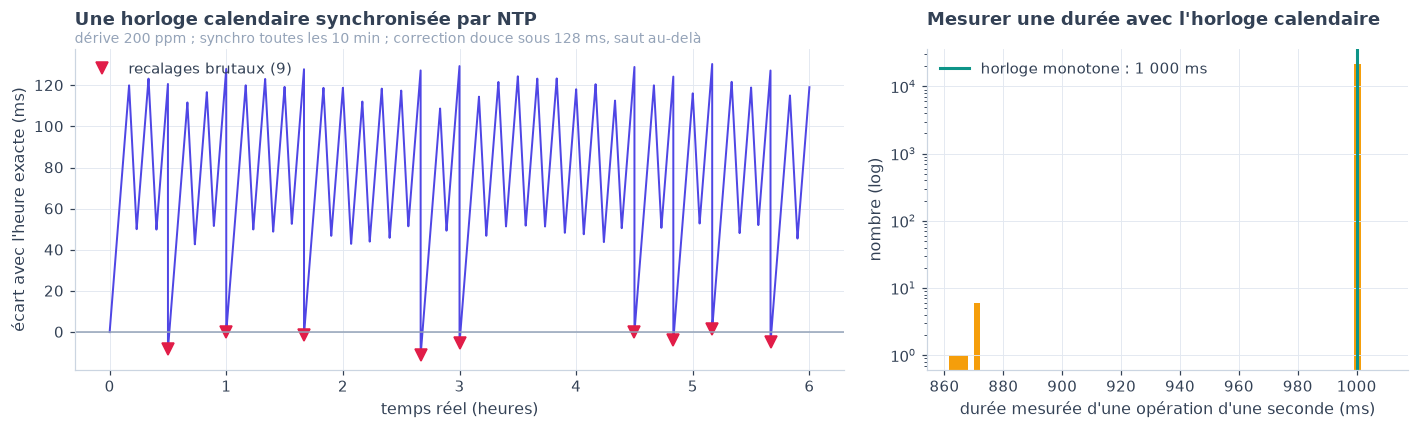

durée mesurée : min 861 ms, max 1000.2 ms ; 0.04% des mesures fausses de plus de 1 ms


In [3]:
tr = ds.tod_clock_trace(duration=6 * 3600, dt=1.0, drift_ppm=200, sync_every=600, sync_error_ms=5,
                        step_threshold_ms=128, seed=4)
t_h = tr["t"] / 3600
off = tr["offset_ms"]
# durée d'une opération d'une seconde mesurée avec l'horloge calendaire
mes = 1000 + np.diff(off)                              # ms
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
ax.plot(t_h, off, color=INDIGO, lw=1.3)
j = np.flatnonzero(tr["jumps"])
ax.plot(t_h[j], off[j], "v", color=ROSE, ms=8, label=f"recalages brutaux ({j.size})")
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("temps réel (heures)"); ax.set_ylabel("écart avec l'heure exacte (ms)")
ax.set_title("Une horloge calendaire synchronisée par NTP")
subtitle(ax, "dérive 200 ppm ; synchro toutes les 10 min ; correction douce sous 128 ms, saut au-delà")
ax.legend(loc="upper left")
ax = axes[1]
ax.hist(mes, bins=np.linspace(min(mes.min(), 870), 1010, 70), color=AMBER, log=True)
ax.axvline(1000, color=TEAL, lw=2, label="horloge monotone : 1 000 ms")
ax.set_xlabel("durée mesurée d'une opération d'une seconde (ms)"); ax.set_ylabel("nombre (log)")
ax.set_title("Mesurer une durée avec l'horloge calendaire")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"durée mesurée : min {mes.min():.0f} ms, max {mes.max():.1f} ms ; "
      f"{np.mean(np.abs(mes - 1000) > 1):.2%} des mesures fausses de plus de 1 ms")

L'horloge s'écarte en dents de scie : 200 ppm, c'est 120 ms de dérive en dix minutes.
Quand l'écart estimé reste sous le seuil, NTP le résorbe en ralentissant l'horloge (les
pentes descendantes) ; quand il le dépasse, l'horloge est **recalée d'un coup** et
recule de plus d'un dixième de seconde. Une opération d'une seconde chronométrée à
cheval sur un recalage paraît durer moins de 0,9 s (elle pourrait même paraître durer un
temps **négatif** si le saut dépassait la seconde) ; pendant les phases de correction
douce, chaque mesure est fausse de quelques dixièmes de milliseconde. Pour mesurer un
délai d'expiration ou un temps de réponse, on utilise donc **toujours** l'horloge
monotone (`time.monotonic()` en Python, `System.nanoTime()` en Java,
`clock_gettime(CLOCK_MONOTONIC)` sous Linux). Sur un serveur à plusieurs processeurs,
le système doit même masquer le fait que chaque processeur a son propre compteur : il
est prudent de ne pas prendre la monotonie pour une garantie absolue.

> **À retenir.** L'horloge calendaire peut sauter en avant et en arrière : elle sert à
> dater, jamais à chronométrer. L'horloge monotone ne recule pas mais n'a de sens que
> sur une seule machine.

## 3. Synchronisation et précision (section *Clock Synchronization and Accuracy*)

Les horloges calendaires doivent être synchronisées pour être utiles, et nos moyens de
le faire sont bien moins fiables qu'on ne l'espère :

- **la dérive du quartz** varie avec la température ; Google suppose jusqu'à **200 ppm**
  pour ses serveurs ;
- une horloge trop éloignée du serveur NTP peut **refuser** de se synchroniser, ou être
  **recalée** brutalement ;
- un nœud accidentellement **coupé des serveurs NTP** par un pare-feu dérive sans que
  personne ne le remarque ;
- la synchronisation ne vaut pas mieux que le **réseau** : une expérience a mesuré une
  erreur minimale de 35 ms sur Internet, avec des pics vers la seconde ;
- certains serveurs NTP sont **faux** de plusieurs heures ;
- les **secondes intercalaires** créent des minutes de 59 ou 61 secondes ;
- dans une **machine virtuelle**, l'horloge est virtualisée et une mise en pause de la VM
  apparaît comme un **saut en avant** ;
- sur les appareils des utilisateurs, l'horloge peut être **délibérément fausse** (pour
  tricher dans un jeu, par exemple).

**La dérive.** 200 ppm, c'est 200 µs d'erreur par seconde écoulée depuis la dernière
synchronisation.

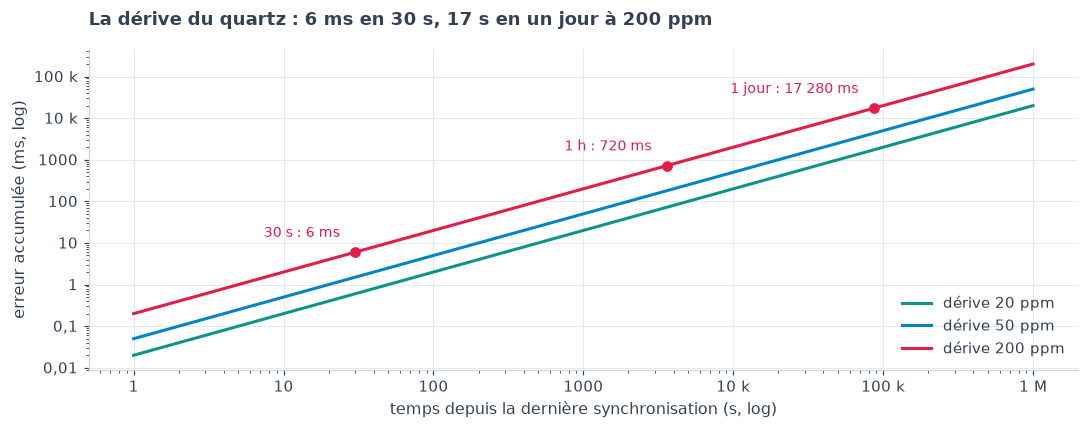

In [4]:
secs = np.logspace(0, 6, 200)
fig, ax = plt.subplots(figsize=(10, 4))
for ppm, c in [(20, TEAL), (50, SKY), (200, ROSE)]:
    ax.loglog(secs, ds.drift_error(ppm, secs) * 1e3, color=c, label=f"dérive {ppm} ppm")
for s_, lab in [(30, "30 s"), (3600, "1 h"), (86400, "1 jour")]:
    e = ds.drift_error(200, s_) * 1e3
    ax.plot(s_, e, "o", color=ROSE)
    ax.annotate(f"{lab} : {e:,.0f} ms".replace(",", " "), (s_, e), xytext=(-10, 10), textcoords="offset points",
                ha="right", fontsize=9, color=ROSE)
plain_log_axis(ax)
ax.set_xlabel("temps depuis la dernière synchronisation (s, log)"); ax.set_ylabel("erreur accumulée (ms, log)")
ax.set_title("La dérive du quartz : 6 ms en 30 s, 17 s en un jour à 200 ppm")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Comment NTP estime l'écart.** Le client note l'instant d'émission $t_0$ (sur son
horloge), le serveur note la réception $t_1$ et l'émission de sa réponse $t_2$ (sur la
sienne), le client note la réception $t_3$. En supposant le réseau **symétrique**, l'écart
et le délai aller-retour valent

$$\theta = \frac{(t_1 - t_0) + (t_2 - t_3)}{2}, \qquad \delta = (t_3 - t_0) - (t_2 - t_1).$$

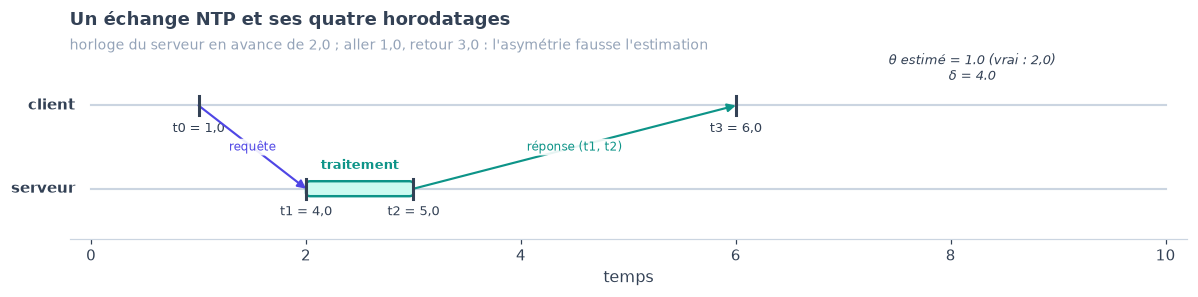

In [5]:
st = SpaceTime(["client", "serveur"], t_max=10, width=11, title="Un échange NTP et ses quatre horodatages",
               subtitle="horloge du serveur en avance de 2,0 ; aller 1,0, retour 3,0 : l'asymétrie fausse l'estimation")
st.msg("client", 1.0, "serveur", 2.0, "requête", color=INDIGO)
st.op("serveur", 2.0, 3.0, "traitement", color=TEAL)
st.msg("serveur", 3.0, "client", 6.0, "réponse (t1, t2)", color=TEAL)
for node, t, lab in [("client", 1.0, "t0 = 1,0"), ("serveur", 2.0, "t1 = 4,0"), ("serveur", 3.0, "t2 = 5,0"),
                     ("client", 6.0, "t3 = 6,0")]:
    st.event(node, t, lab, kind="tick")
off_, dly = ds.ntp_offset_delay(1.0, 4.0, 5.0, 6.0)
st.note(8.2, "client", f"θ estimé = {off_:.1f} (vrai : 2,0)\nδ = {dly:.1f}", dy=0.45, color=SLATE)
st.show()

Ici le serveur avance de 2,0, l'aller dure 1,0 et le retour 3,0. Le calcul donne
$\theta = ((4-1) + (5-6))/2 = 1{,}0$ : une erreur de 1,0, soit exactement
$(d_\text{aller} - d_\text{retour})/2$. L'erreur est donc **nulle si le réseau est
symétrique** et **bornée par $\delta/2$** dans tous les cas : NTP ne peut pas être plus
précis que la moitié de l'aller-retour. Vérifions sur 5 000 échanges simulés, sur un
réseau local et sur Internet.

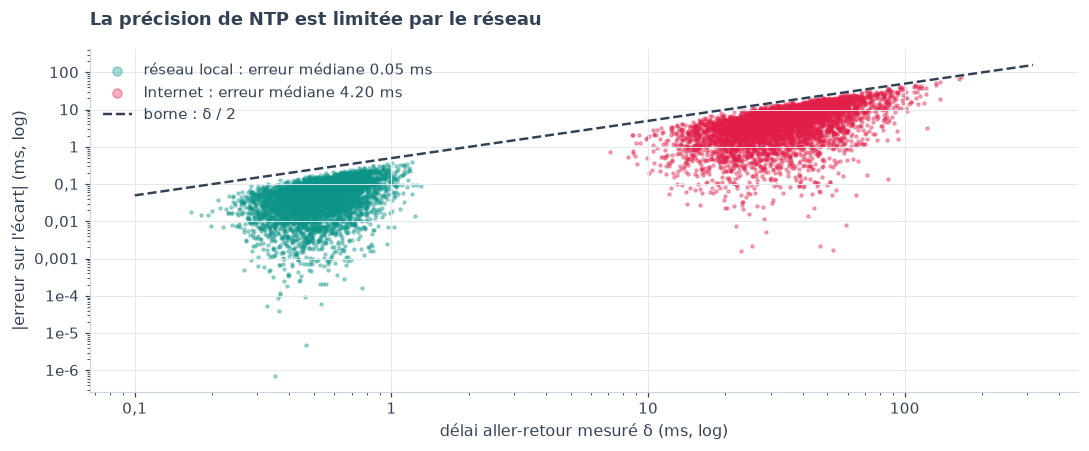

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for nom, med, sig, c in [("réseau local", 0.25, 0.4, TEAL), ("Internet", 15.0, 0.6, ROSE)]:
    d_out = med * np.exp(sig * rng.standard_normal(5000))
    d_back = med * np.exp(sig * rng.standard_normal(5000))
    est = np.array([ds.ntp_exchange(3.0, a, b) for a, b in zip(d_out, d_back)])
    ax.scatter(est[:, 1], np.abs(est[:, 2]), s=4, color=c, alpha=0.35, label=f"{nom} : erreur médiane {np.median(np.abs(est[:, 2])):.2f} ms")
dd = np.logspace(-1, 2.5, 50)
ax.plot(dd, dd / 2, color=SLATE, lw=1.6, ls="--", label="borne : δ / 2")
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax)
ax.set_xlabel("délai aller-retour mesuré δ (ms, log)"); ax.set_ylabel("|erreur sur l'écart| (ms, log)")
ax.set_title("La précision de NTP est limitée par le réseau")
ax.legend(loc="upper left", markerscale=3)
plt.tight_layout(); plt.show()

Sur un réseau local, l'erreur se compte en dixièmes de milliseconde ; sur Internet, en
millisecondes, voire dizaines de millisecondes. Tous les points restent sous la droite
$\delta/2$ : quand on ne connaît pas l'asymétrie, c'est la meilleure garantie possible.

**Plusieurs serveurs, dont un menteur.** Un client NTP interroge plusieurs serveurs et
écarte les valeurs aberrantes. Chaque réponse définit un intervalle « l'heure exacte est
dans $[\theta - \delta/2, \theta + \delta/2]$ » ; l'**algorithme de Marzullo**
(`ds.marzullo`) cherche le plus petit intervalle compatible avec le plus grand nombre de
serveurs. Un serveur mal configuré, faux de plusieurs secondes, est simplement minoritaire.

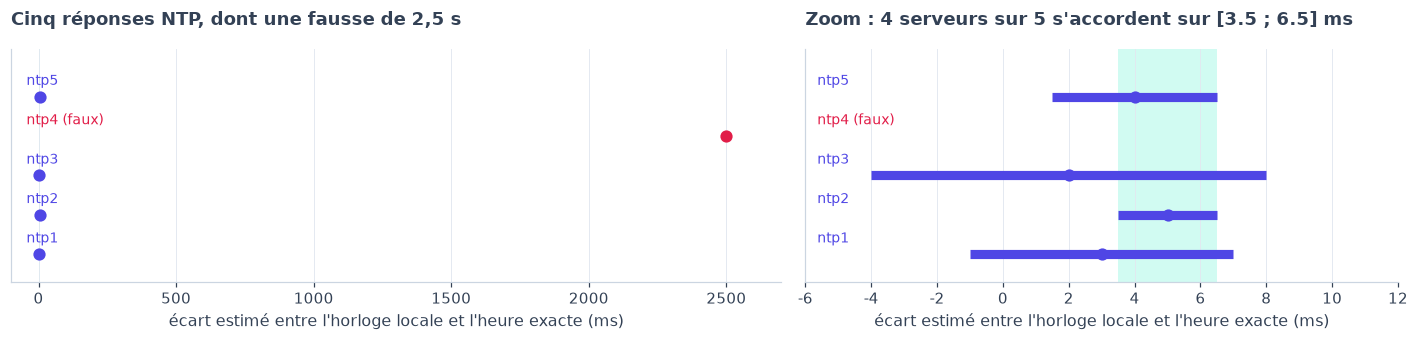

In [7]:
serveurs = {"ntp1": (3.0, 8.0), "ntp2": (5.0, 3.0), "ntp3": (2.0, 12.0), "ntp4 (faux)": (2500.0, 6.0),
            "ntp5": (4.0, 5.0)}
intervals = [(o - dl / 2, o + dl / 2) for o, dl in serveurs.values()]
k, lo, hi = ds.marzullo(intervals)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
for ax, xl in zip(axes, [(-100, 2700), (-6, 12)]):
    for y, ((nom, _), (a, b)) in enumerate(zip(serveurs.items(), intervals)):
        c = ROSE if "faux" in nom else INDIGO
        ax.plot([a, b], [y, y], color=c, lw=6, solid_capstyle="butt")
        ax.plot([(a + b) / 2], [y], "o", color=c, ms=7)
        ax.text(xl[0] + 0.02 * (xl[1] - xl[0]), y + 0.3, nom, fontsize=9, color=c)
    ax.axvspan(lo, hi, color=LIGHT[TEAL], alpha=0.9, lw=0)
    ax.set_xlim(*xl); ax.set_yticks([]); ax.set_ylim(-0.7, len(serveurs) + 0.2)
    ax.set_xlabel("écart estimé entre l'horloge locale et l'heure exacte (ms)")
axes[0].set_title("Cinq réponses NTP, dont une fausse de 2,5 s")
axes[1].set_title(f"Zoom : {k} serveurs sur 5 s'accordent sur [{lo:.1f} ; {hi:.1f}] ms")
plt.tight_layout(); plt.show()

**Secondes intercalaires et lissage.** Une seconde intercalaire fait durer une minute 61
secondes ; des logiciels qui ne l'avaient pas prévu ont planté en masse. Une parade est de
faire « mentir » les serveurs NTP en répartissant la seconde supplémentaire sur une
journée entière (**lissage**, leap smear), au prix d'un désaccord temporaire avec les
serveurs qui ne lissent pas.

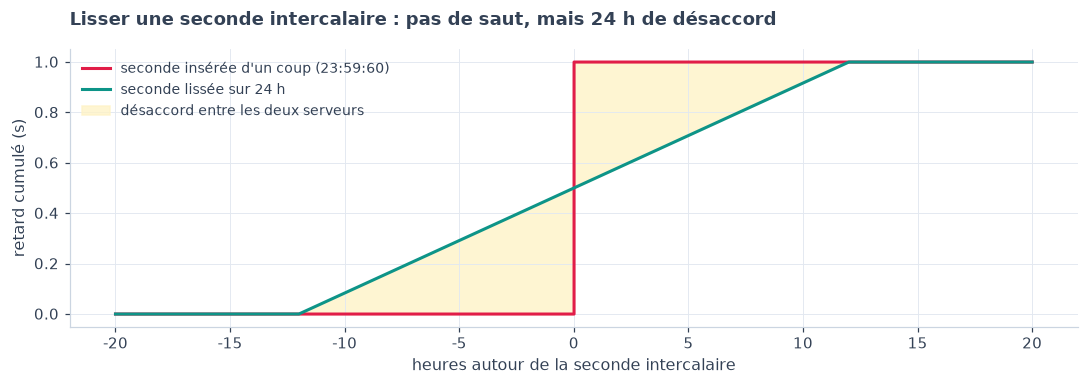

In [8]:
tt = np.linspace(-20 * 3600, 20 * 3600, 2000)
step = (tt >= 0).astype(float)
smear = ds.smeared_offset(tt, 0.0, window=86_400)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.step(tt / 3600, step, where="post", color=ROSE, lw=2, label="seconde insérée d'un coup (23:59:60)")
ax.plot(tt / 3600, smear, color=TEAL, lw=2, label="seconde lissée sur 24 h")
ax.fill_between(tt / 3600, smear, step, color=LIGHT[AMBER], alpha=0.8, label="désaccord entre les deux serveurs")
ax.set_xlabel("heures autour de la seconde intercalaire"); ax.set_ylabel("retard cumulé (s)")
ax.set_title("Lisser une seconde intercalaire : pas de saut, mais 24 h de désaccord")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

**Quand on s'en donne les moyens.** Une précision excellente est possible : la
réglementation européenne MiFID II impose aux fonds de trading à haute fréquence de
synchroniser leurs horloges à **100 µs** près de l'UTC (pour analyser les krachs éclairs
et détecter les manipulations). Il faut pour cela du matériel spécial (récepteurs GPS,
horloges atomiques), le protocole **PTP** (Precision Time Protocol) et une surveillance
soigneuse. Un démon NTP mal configuré ou un pare-feu qui bloque NTP suffit, lui, à faire
grandir l'erreur très vite.

> **À retenir.** Une horloge synchronisée par NTP a une erreur de l'ordre de la
> milliseconde au mieux sur un réseau local, de dizaines de millisecondes sur Internet,
> et bien pire en cas de mauvaise configuration. NTP ne fait pas mieux que la moitié de
> l'aller-retour, et la dérive reprend dès qu'il cesse de synchroniser.

## 4. Horodater pour ordonner : le piège de « la dernière écriture gagne » (section *Timestamps for ordering events*)

Le problème des horloges est qu'elles **semblent** simples. Une journée n'a pas toujours
86 400 secondes, l'horloge calendaire peut reculer, et deux nœuds n'ont pas la même
heure. Pire, une horloge fausse passe **inaperçue** : un processeur défectueux fait
planter la machine, alors qu'un quartz qui dérive laisse tout fonctionner en apparence.
Si un logiciel dépend d'horloges synchronisées, le résultat le plus probable est une
**perte de données silencieuse** plutôt qu'un plantage. D'où le conseil du livre :
surveiller les écarts d'horloge de tous les nœuds, et exclure un nœud qui dérive trop.

Un usage tentant mais dangereux est d'**ordonner** des écritures concurrentes avec leurs
horodatages, comme la stratégie **LWW** (last write wins, chapitre 5) :
chaque réplique garde la valeur de plus grand horodatage. Rejouons sur `ddia.sim` un
scénario de réplication multi-leader (classe `ds.LWWReplica`), le temps étant compté en
millisecondes. L'horloge du nœud 1 avance de 3 ms sur celle du nœud 3 : une
synchronisation **excellente**, meilleure que ce qu'on obtient souvent.

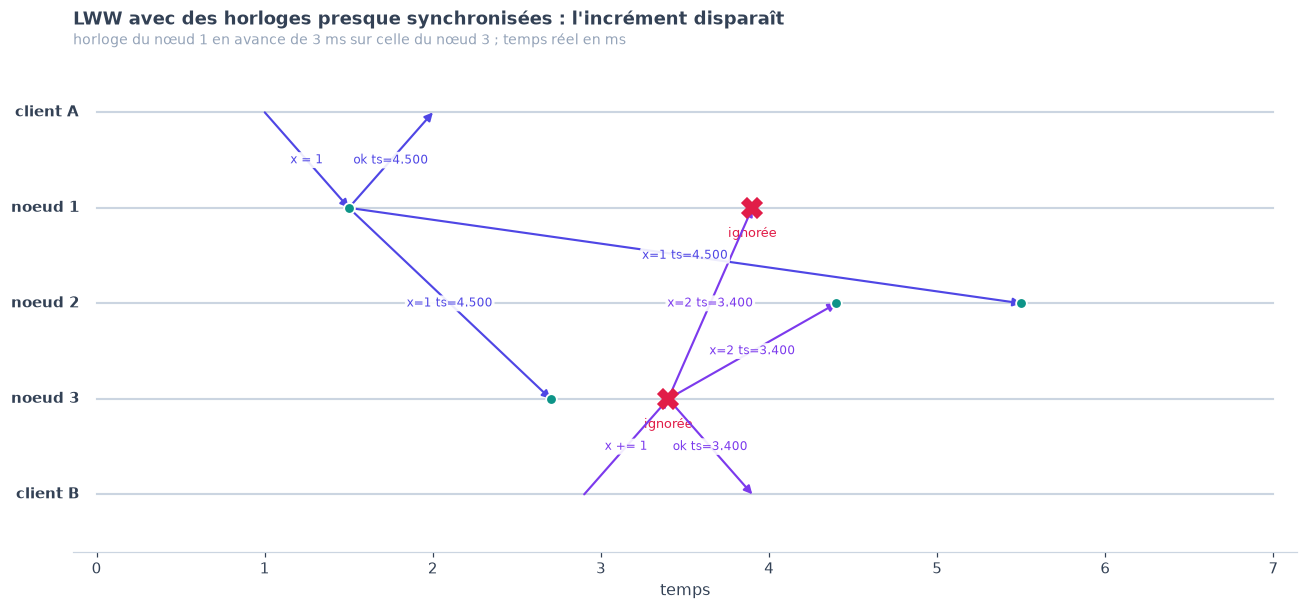

,réplique,valeur,horodatage (ms)
0,noeud 1,1,42004.5
1,noeud 2,1,42004.5
2,noeud 3,1,42004.5


In [9]:
class ClientLWW(Node):
    def on_message(self, src, msg):
        self.record(f"{msg[0]} x={msg[1]} (ts {msg[2]:.3f})")


net = Network(seed=1, latency=lambda r, s, d: {("noeud 1", "noeud 3"): 1.2, ("noeud 1", "noeud 2"): 4.0,
                                               ("noeud 3", "noeud 2"): 1.0}.get((s, d), 0.5))
peers = ["noeud 1", "noeud 2", "noeud 3"]
reps = {p: net.add(ds.LWWReplica(p, [q for q in peers if q != p], clock=Clock(offset=o)))
        for p, o in zip(peers, [42_003.0, 42_001.0, 42_000.0])}
ca, cb = net.add(ClientLWW("client A")), net.add(ClientLWW("client B"))
net.at(1.0, ca.send, "noeud 1", ("set", 1))
net.at(2.9, cb.send, "noeud 3", ("incr",))
net.run()
st = SpaceTime(["client A", "noeud 1", "noeud 2", "noeud 3", "client B"], t_max=7, width=12,
               title="LWW avec des horloges presque synchronisées : l'incrément disparaît",
               subtitle="horloge du nœud 1 en avance de 3 ms sur celle du nœud 3 ; temps réel en ms")
def lab(dl):
    m = dl.msg
    if m[0] == "set":
        return "x = 1"
    if m[0] == "incr":
        return "x += 1"
    if m[0] == "repl":
        return f"x={m[1]} ts={m[2] - 42000:.3f}"
    return f"ok ts={m[2] - 42000:.3f}"
st.from_trace(net.trace, label_of=lab, color_of=lambda dl: INDIGO if dl.msg[0] in ("set", "ok") and (dl.src == "client A" or dl.dst == "client A") else (VIOLET if "B" in dl.src + dl.dst else (INDIGO if dl.src == "noeud 1" else VIOLET)))
for p, r in reps.items():
    for (t, origin, val, ts, kept) in r.history:
        st.event(p, t, "" if kept else "ignorée", kind="point" if kept else "crash", color=TEAL if kept else ROSE)
st.show()
pd.DataFrame([dict(réplique=p, valeur=r.value, **{"horodatage (ms)": round(r.ts, 3)}) for p, r in reps.items()])

Le client A écrit $x = 1$ sur le nœud 1, horodaté 42 004,5 ms par l'horloge en avance du
nœud 1 (les étiquettes de la figure omettent le préfixe 42 000). L'écriture est répliquée
au nœud 3, où le client B **l'incrémente** : $x = 2$, horodaté 42 003,4 ms par l'horloge du
nœud 3... soit **avant** l'écriture qu'il a lue, bien qu'il ait eu lieu 1,9 ms plus tard.
Partout, LWW garde $x = 1$ et jette l'incrément, y compris sur le nœud 3 lui-même, qui
a pourtant répondu « ok » au client B. L'écriture de B, **causalement postérieure**,
porte un horodatage plus petit : elle disparaît sans qu'aucune erreur ne soit signalée.

Ce n'est pas un accident de réglage : tant que deux écritures sur la même clé sont plus
proches dans le temps que l'écart entre les horloges, LWW peut les ordonner à l'envers.
Mesurons la proportion d'écritures perdues (`ds.lww_lost_writes`) selon le rapport entre
l'écart des horloges et l'intervalle moyen entre deux écritures.

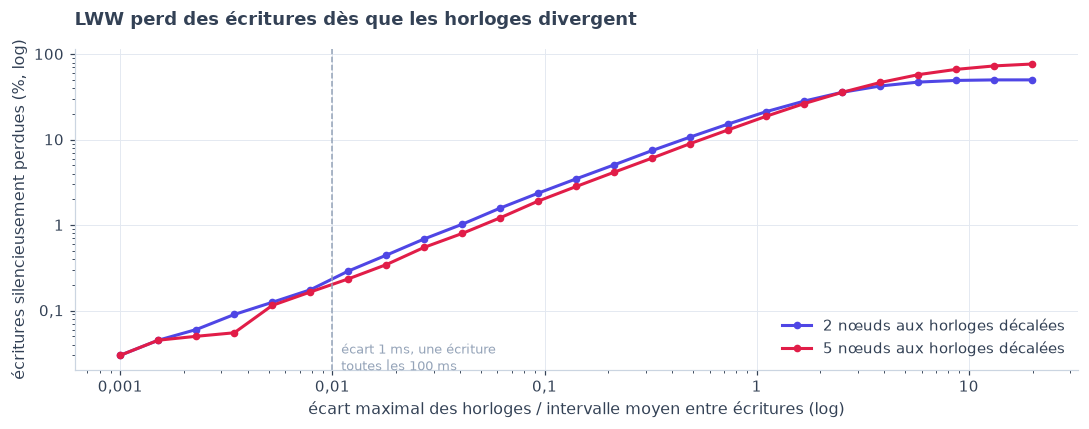

In [10]:
ratios = np.logspace(-3, 1.3, 25)
fig, ax = plt.subplots(figsize=(10, 4))
for nn, c in [(2, INDIGO), (5, ROSE)]:
    lost = [ds.lww_lost_writes(r, n_writes=20_000, mean_gap=1.0, n_nodes=nn, seed=3)["perdues"] * 100 for r in ratios]
    ax.plot(ratios, lost, "o-", ms=4, color=c, label=f"{nn} nœuds aux horloges décalées")
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax)
ax.axvline(0.01, color=GRAY, ls="--", lw=1)
ax.text(0.011, 0.02, "écart 1 ms, une écriture\ntoutes les 100 ms", fontsize=8.5, color=GRAY)
ax.set_xlabel("écart maximal des horloges / intervalle moyen entre écritures (log)")
ax.set_ylabel("écritures silencieusement perdues (%, log)")
ax.set_title("LWW perd des écritures dès que les horloges divergent")
ax.legend()
plt.tight_layout(); plt.show()

Avec un écart de 1 ms et une écriture toutes les 100 ms sur la même clé, environ une
écriture sur 400 disparaît ; quand l'écart atteint l'intervalle entre écritures, c'est
une sur cinq, ou davantage. Le livre souligne trois défauts de LWW avec des horloges
physiques :

- des écritures **disparaissent mystérieusement** : un nœud en retard ne peut pas écraser
  une valeur écrite par un nœud en avance tant que l'écart n'est pas écoulé ;
- LWW **ne distingue pas** des écritures successives rapides (B a lu l'écriture de A) et
  des écritures **vraiment concurrentes** ; il faut des vecteurs de versions pour cela
  (chapitre 5) ;
- deux nœuds peuvent produire le **même** horodatage (résolution à la milliseconde) : il
  faut un départage arbitraire, qui peut lui aussi violer la causalité.

On peut éviter la perte en imposant qu'une nouvelle valeur ait toujours un horodatage
**plus grand** que celle qu'elle remplace, quitte à dépasser l'horloge locale, mais cela
coûte une lecture supplémentaire ; Cassandra et ScyllaDB s'en dispensent et utilisent
l'horloge du client. Et l'on ne peut pas espérer une synchronisation assez fine : il
faudrait une erreur d'horloge bien plus petite que le délai réseau, alors que la précision
de NTP est **elle-même limitée par ce délai** (section 3). Même finement synchronisé, un
paquet envoyé à 100 ms (horloge de l'émetteur) peut arriver à 99 ms (horloge du
récepteur) : il semble arrivé avant d'être parti.

Les **horloges logiques**, fondées sur des compteurs plutôt que sur un quartz, sont
l'alternative sûre pour ordonner des événements : elles ne mesurent ni l'heure ni les
durées, seulement l'ordre relatif (chapitre 9). Par opposition, les
horloges calendaires et monotones sont dites **physiques**.

> **À retenir.** Ordonner des écritures par horodatage physique (LWW) perd silencieusement
> des écritures causalement postérieures dès que l'écart entre horloges dépasse
> l'intervalle entre écritures. Pour l'ordre, il faut des horloges logiques.

## 5. Intervalle de confiance et instantanés globaux (sections *Clock readings have a confidence interval* et *Synchronized clocks for global snapshots*)

On peut lire une horloge à la microseconde, voire à la nanoseconde : cela ne la rend pas
**exacte** à ce niveau. Avec un serveur NTP local et une synchronisation par minute, la
dérive atteint déjà plusieurs millisecondes ; via Internet, l'erreur se compte en dizaines
de millisecondes et peut dépasser 100 ms en cas de congestion. Une lecture d'horloge est
donc moins un **instant** qu'un **intervalle de confiance** : « l'heure est entre 10,3 et
10,5 s après la minute ». L'incertitude se calcule : dérive possible depuis la dernière
synchronisation, plus incertitude du serveur, plus délai aller-retour.

La plupart des API (`clock_gettime`) ne disent rien de cette incertitude. Exception
notable : l'API **TrueTime** de Google Spanner renvoie un intervalle
$[\text{au plus tôt}, \text{au plus tard}]$ qui contient à coup sûr l'heure exacte. Voici
une horloge de ce type (`ds.TrueTime`) : incertitude de 1 ms juste après une
synchronisation, qui grandit de 200 µs par seconde jusqu'à la suivante, 30 s plus tard.

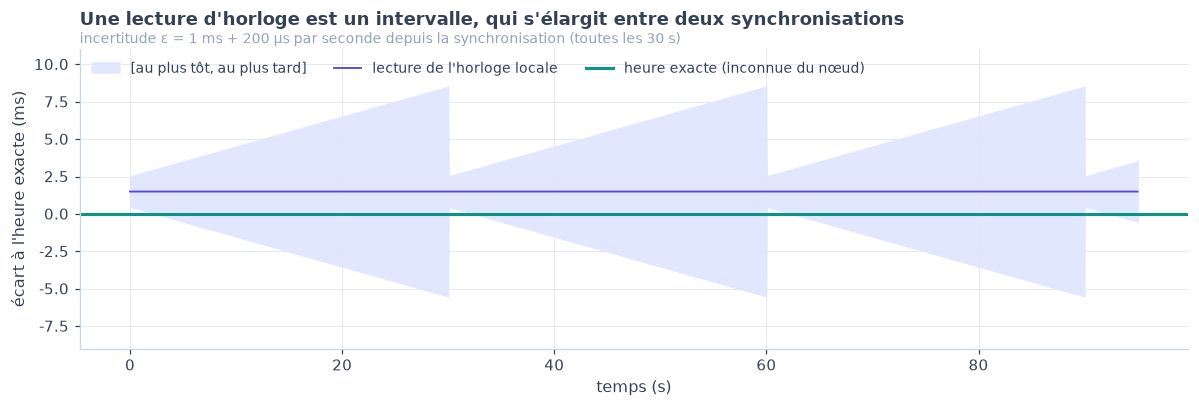

In [11]:
tt_ = np.linspace(0, 95, 2000)
clk = ds.TrueTime(base=1e-3, drift_ppm=200, sync_every=30, true_offset=0.0015)
lohi = np.array([clk.now(t) for t in tt_])
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(tt_, (lohi[:, 0] - tt_) * 1e3, (lohi[:, 1] - tt_) * 1e3, color=LIGHT[INDIGO], label="[au plus tôt, au plus tard]")
ax.plot(tt_, (lohi.mean(axis=1) - tt_) * 1e3, color=INDIGO, lw=1.2, label="lecture de l'horloge locale")
ax.axhline(0, color=TEAL, lw=2, label="heure exacte (inconnue du nœud)")
ax.set_xlabel("temps (s)"); ax.set_ylabel("écart à l'heure exacte (ms)")
ax.set_title("Une lecture d'horloge est un intervalle, qui s'élargit entre deux synchronisations")
subtitle(ax, "incertitude ε = 1 ms + 200 µs par seconde depuis la synchronisation (toutes les 30 s)")
ax.legend(loc="upper left", fontsize=9, ncol=3)
ax.set_ylim(-9, 11)
plt.tight_layout(); plt.show()

**Pourquoi c'est utile : les instantanés globaux.** L'isolation par instantané (MVCC,
chapitre 7) demande des identifiants de transaction **croissants** qui
respectent la **causalité** : si B lit ou écrase ce qu'a écrit A, l'identifiant de B doit
être plus grand. Sur une seule machine, un compteur suffit ; sur une base répartie entre
partitions et centres de données, un compteur global exige une coordination qui devient un
goulet d'étranglement. Peut-on prendre comme identifiants les horodatages d'horloges
synchronisées ? Le problème est précisément leur incertitude.

Spanner s'appuie sur une observation simple : si deux intervalles **ne se chevauchent
pas** ($A_\text{au plus tard} < B_\text{au plus tôt}$), alors B est certainement postérieur
à A ; s'ils se chevauchent, on ne sait pas.

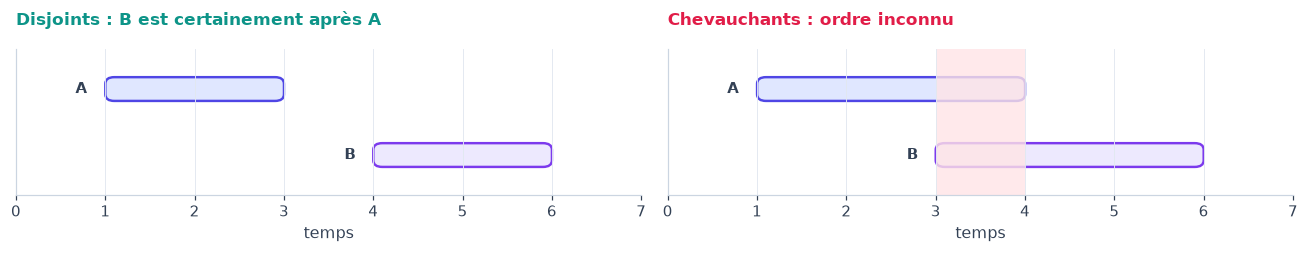

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 2.4))
for ax, (a, b), titre, c in zip(axes, [((1, 3), (4, 6)), ((1, 4), (3, 6))],
                               ["Disjoints : B est certainement après A", "Chevauchants : ordre inconnu"], [TEAL, ROSE]):
    for y, (lo_, hi_), nom in [(1, a, "A"), (0, b, "B")]:
        ax.add_patch(FancyBboxPatch((lo_, y - 0.18), hi_ - lo_, 0.36, boxstyle="round,pad=0,rounding_size=0.1",
                                    fc=LIGHT[INDIGO if nom == "A" else VIOLET], ec=INDIGO if nom == "A" else VIOLET, lw=1.6))
        ax.text(lo_ - 0.2, y, nom, ha="right", va="center", fontweight="bold")
    if a[1] > b[0]:
        ax.axvspan(b[0], a[1], color=LIGHT[ROSE], alpha=0.8, lw=0)
    ax.set_xlim(0, 7); ax.set_ylim(-0.6, 1.6); ax.set_yticks([]); ax.set_xlabel("temps")
    ax.set_title(titre, color=c, fontsize=11)
plt.tight_layout(); plt.show()

D'où la règle du **commit wait** : avant de valider une transaction en lecture-écriture,
Spanner prend comme horodatage la borne « au plus tard » de son horloge, puis **attend**
que la borne « au plus tôt » l'ait dépassée (environ $2\varepsilon$). Toute transaction qui
pourra lire ses données commencera après, avec un intervalle disjoint. Simulons des
transactions causales en chaîne sur quatre nœuds dont les horloges sont décalées dans
$\pm\varepsilon$ (`ds.commit_wait_experiment`).

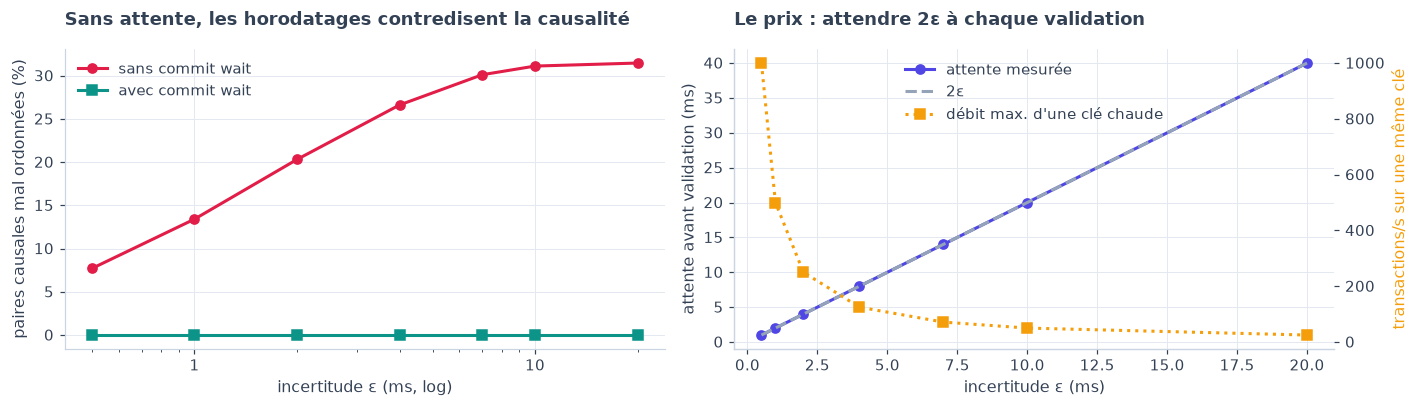

,eps_ms,inversions_sans,inversions_avec,attente_ms
0,0.5,7.70,0.0,1.0
1,1.0,13.41,0.0,2.0
2,2.0,20.31,0.0,4.0
3,4.0,26.61,0.0,8.0
4,7.0,30.12,0.0,14.0
5,10.0,31.12,0.0,20.0
6,20.0,31.47,0.0,40.0


In [13]:
eps_ms = np.array([0.5, 1, 2, 4, 7, 10, 20])
rows = []
for e in eps_ms:
    sans = ds.commit_wait_experiment(eps=e / 1e3, gap=2e-3, commit_wait=False, seed=1)
    avec = ds.commit_wait_experiment(eps=e / 1e3, gap=2e-3, commit_wait=True, seed=1)
    rows.append(dict(eps_ms=e, inversions_sans=sans["inversions"] * 100, inversions_avec=avec["inversions"] * 100,
                     attente_ms=avec["attente_moy"] * 1e3))
CW = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.plot(CW.eps_ms, CW.inversions_sans, "o-", color=ROSE, label="sans commit wait")
ax.plot(CW.eps_ms, CW.inversions_avec, "s-", color=TEAL, label="avec commit wait")
ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlabel("incertitude ε (ms, log)"); ax.set_ylabel("paires causales mal ordonnées (%)")
ax.set_title("Sans attente, les horodatages contredisent la causalité")
ax.legend()
ax = axes[1]
ax.plot(CW.eps_ms, CW.attente_ms, "o-", color=INDIGO, label="attente mesurée")
ax.plot(CW.eps_ms, 2 * CW.eps_ms, "--", color=GRAY, label="2ε")
ax2 = ax.twinx()
ax2.plot(CW.eps_ms, 1000 / (2 * CW.eps_ms), "s:", color=AMBER, label="débit max. d'une clé chaude")
ax2.set_ylabel("transactions/s sur une même clé", color=AMBER); ax2.grid(False)
ax.set_xlabel("incertitude ε (ms)"); ax.set_ylabel("attente avant validation (ms)")
ax.set_title("Le prix : attendre 2ε à chaque validation")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center")
plt.tight_layout(); plt.show()
CW.round(2)

Sans attente, de 8 % à 30 % des transactions (selon l'incertitude) reçoivent un
horodatage plus petit que celle dont elles dépendent ; avec le commit wait, aucune. Le prix est une attente de $2\varepsilon$
par validation, qui borne aussi le débit des transactions qui se suivent sur une même
donnée. D'où l'intérêt de garder $\varepsilon$ petit : Google installe un récepteur GPS ou
une horloge atomique dans chaque centre de données, ce qui ramène l'incertitude à environ
7 ms. Ces équipements ne sont pas indispensables au principe : l'essentiel est de
**connaître** l'intervalle de confiance, les bonnes horloges servant seulement à le
rétrécir.

> **À retenir.** Une lecture d'horloge n'a de sens qu'avec son incertitude. En la
> connaissant (TrueTime), on peut ordonner des événements de façon sûre lorsque les
> intervalles sont disjoints, au prix d'une attente de l'ordre de deux fois
> l'incertitude (commit wait de Spanner).